# TP 2: Autoencoder (AE), Variational Autoencoder (VAE) Generative Adversarial Networks (GAN)

## Objective: Implement a AE, VAE & GAN with Pytorch

## Load packages

In [1]:
import scipy
import numpy as np # manipulate N-dimensional arrays
import pandas as pd # data frame
import matplotlib.pyplot as plt # data plotting
import seaborn # advanced data plotting
from sklearn import preprocessing # basic ML models
# import scipy # scientific computing library

import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

Set the device

In [2]:
device = "cuda:0" if torch.cuda.is_available() else "cpu" #0 indicates the GPU you gonna use
print(f"Using {device} device")

Using cuda:0 device


## a) Load and preprocess the data

#### Description of the data:
There are  labeled subsets of the 10 handwritten digits and consists of 70000 **28x28** grayscale images of 10 classes, with 7000 images per class. There are **60000 training images** and **10000 test images**. Source: http://yann.lecun.com/exdb/mnist/

No need to download the labels as we will not perform classification. We use only a training set.

The data can be directly downloaded with PyTorch. Please visit the following website: https://pytorch.org/vision/stable/datasets.html.
The dataset must have the same number of channels as the original dataset used for the pretrained model.

In [3]:
from torchvision import datasets
from torchvision import transforms

# set transformation
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,), (0.5,))])

traindata = datasets.MNIST(
    root="~/data",
    train=True,
    download=True,
    transform=transform
)

testdata = datasets.MNIST(
    root="~/data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.5MB/s]


In [4]:
traindata

Dataset MNIST
    Number of datapoints: 60000
    Root location: /root/data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5,), std=(0.5,))
           )

In [5]:
traindata.data.float().std(axis=(0,1,2))

tensor(78.5675)

In [6]:
traindata[0][0].shape

torch.Size([1, 28, 28])

Plot one image with imshow :

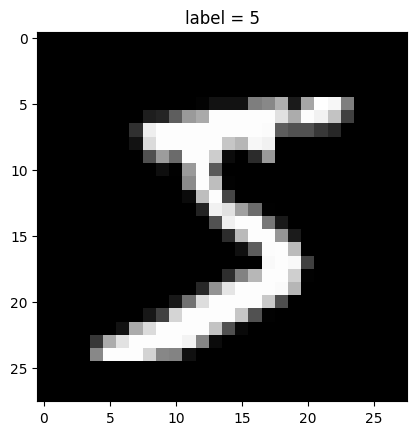

In [10]:
plt.imshow(traindata[0][0].squeeze(), cmap='gray')
plt.title(f"label = {traindata[0][1]}")
plt.show()

In [13]:
num_examples = len(traindata)
num_examples

60000

Convert to dataloader :

In [14]:
batch_size = 64
train_loader = torch.utils.data.DataLoader(traindata, batch_size=batch_size, shuffle=True)
test_loader  = torch.utils.data.DataLoader(testdata,  batch_size=batch_size, shuffle=False)

In [15]:
img_batch,_ = next(iter(train_loader))
print(img_batch.min(),img_batch.max())

tensor(-1.) tensor(1.)


Questions:
- What are the dimensions of the data ?
- What does each value represent ? (RGB, greyscale, other)
- What is the range of the values ?
- What is the difference with the CIFAR dataset ?

1. 数据维度： 每张图是 1×28×28，展平后是 784 维（后面 AE 的输入维度 784 就是这么来的）。一个 batch 的形状是 [64, 1, 28, 28]。

2. 每个值代表什么： greyscale（灰度）强度，只有 1 个通道，不是 RGB。

3. 取值范围： 原始数据是 0–255；ToTensor 之后是 [0, 1]；Normalize 之后是 [−1, 1]。

4. 和 CIFAR-10 的区别： CIFAR-10 是 3×32×32 的 RGB 彩色图，内容是飞机、猫这类自然物体，背景复杂，训练集 50000 张。MNIST 是单通道、背景干净、居中的手写数字，简单得多，所以这里用 MLP 就能做得不错。



## b) Autoencoder

An autoencoder is composed of two neural networks:
- an **encoder** $f$ : which maps an input to a latent representation
- a **decoder** $g$ : which reconstructs the input from the representation

A latent representation is noted $z = f(x)$ and the reconstructed input $\hat{x} = g(z)$.

The model is trained by minimizing the reconstruction error :
$$ \mathcal{L}_{\mathrm{AE}} = \|x-\hat{x}\|^{2} $$

Therefore, we do not need labels for our data.

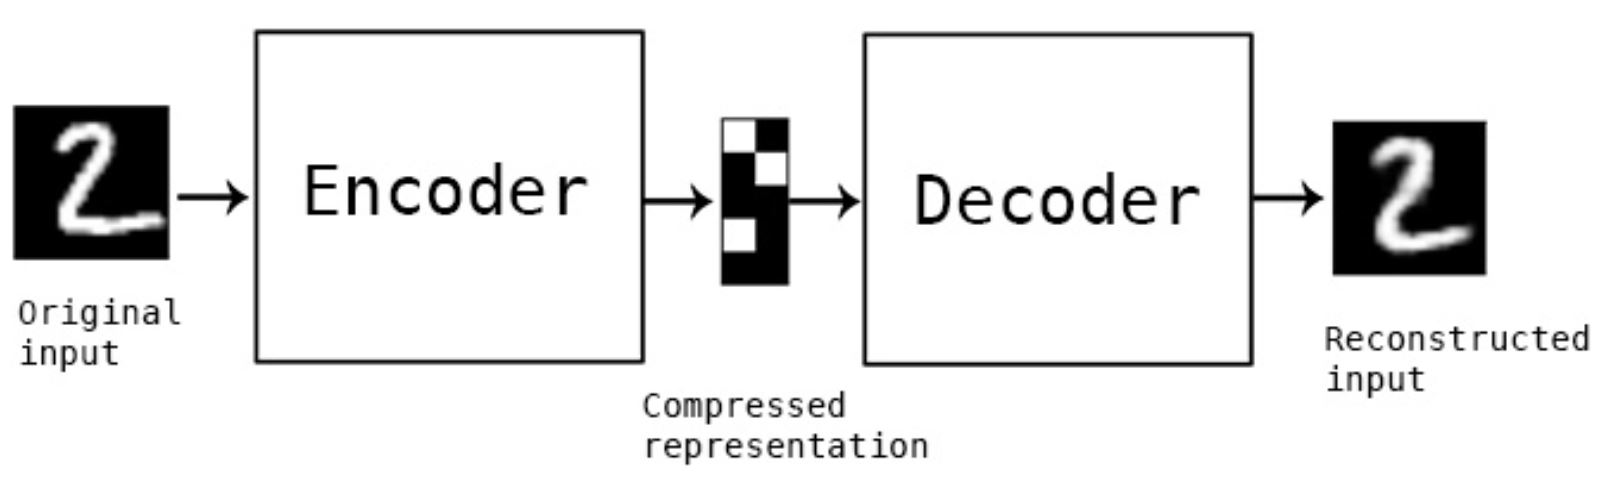

### Implementation

Implement an autoencoder architecture following the dimensions:<br>
784 (input dim) $\rightarrow$ 256 $\rightarrow$ 64 (latent dim) $\rightarrow$ 256 $\rightarrow$ 784

Note: You can add BatchNorm and Dropout to improve the model but it is not necessary.

In [16]:
import torch.nn as nn

class AE(nn.Module):
    def __init__(self, input_shape, intermediate_shape, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),                                   # [B,1,28,28] → [B,784]
            nn.Linear(input_shape, intermediate_shape),     # 784 → 256
            nn.ReLU(),
            nn.Linear(intermediate_shape, latent_dim),      # 256 → 64
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, intermediate_shape),      # 64 → 256
            nn.ReLU(),
            nn.Linear(intermediate_shape, input_shape),     # 256 → 784
            nn.Tanh(),                                      # 输出压到 (-1, 1)
        )

    def forward(self, x):
        z = self.encoder(x)        # 压缩
        x_hat = self.decoder(z)    # 还原
        return x_hat, z

Instantiate the model

In [17]:
ae = AE(input_shape=784, intermediate_shape=256, latent_dim=64)
ae.to(device)

AE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Tanh()
  )
)

Set the criterion and the optimizer

In [18]:
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(ae.parameters(), lr=0.001)

Launch the training. We define two functions :

In [19]:
def train_ae(model, train_loader, optimizer, criterion, device):
    model.train()
    loss_train = []
    for batch in train_loader:
        img_batch, _ = batch
        img_batch = img_batch.view(-1, 784).to(device)

        optimizer.zero_grad()                  # ① 清空上一步残留的梯度

        x_hat, z = model(img_batch)            # ② forward：前向计算重建图
        loss = criterion(x_hat, img_batch)     # ③ 重建图 vs 原图（原图就是"标签"）
        loss.backward()                        # ④ backward：反向传播，算出每个参数的梯度
        optimizer.step()                       # ⑤ 按梯度更新参数

        loss_train.append(loss.item())
    return np.mean(loss_train)


def eval_ae(model, test_loader, criterion, device):
    model.eval()
    loss_eval = []
    with torch.no_grad():
        for batch in test_loader:
            img_batch, _ = batch
            img_batch = img_batch.view(-1, 784).to(device)

            x_hat, _ = model(img_batch)        # 只做 forward
            loss = criterion(x_hat, img_batch)

            loss_eval.append(loss.item())
    return np.mean(loss_eval)

In [20]:
from tqdm import tqdm

epochs = 10
loss_train_history =[]
loss_test_history = []

model = AE(input_shape=784, intermediate_shape=256, latent_dim=64)
model.to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in tqdm(range(epochs)):
    # TODO
    loss_train = train_ae(model, train_loader, optimizer, criterion, device)
    loss_test  = eval_ae(model, test_loader, criterion, device)


    loss_train_history.append(loss_train)
    loss_test_history.append(loss_test)

    print('Epoch {}/{}: train loss: {}'.format(epoch,epochs,loss_train_history[-1]))
    print('Epoch {}/{}: test loss: {}'.format(epoch,epochs,loss_test_history[-1]))

 10%|█         | 1/10 [00:15<02:20, 15.64s/it]

Epoch 0/10: train loss: 0.07647930064609945
Epoch 0/10: test loss: 0.036198109471399315


 20%|██        | 2/10 [00:30<02:02, 15.35s/it]

Epoch 1/10: train loss: 0.03009326500035743
Epoch 1/10: test loss: 0.024925930781444165


 30%|███       | 3/10 [00:46<01:47, 15.34s/it]

...

Epoch 7/10: train loss: 0.01533261784461579
Epoch 7/10: test loss: 0.014766031099115588


 90%|█████████ | 9/10 [02:19<00:15, 15.50s/it]

Epoch 8/10: train loss: 0.014743538580334453
Epoch 8/10: test loss: 0.015256699121254644


100%|██████████| 10/10 [02:34<00:00, 15.49s/it]

Epoch 9/10: train loss: 0.014300423408193248
Epoch 9/10: test loss: 0.014098366366545106


Plot the outputs of the autoencoder using the test set : (1 image per class)

In [21]:
def plot_ae_outputs(net,n=10):
    plt.figure(figsize=(16,4.5))
    targets = testdata.targets.numpy()
    t_idx = {i:np.where(targets==i)[0][0] for i in range(n)}
    for i in range(n):
      ax = plt.subplot(2,n,i+1)
      img = testdata[t_idx[i]][0]
      net.eval()
      with torch.no_grad():
         rec_img  = net(img.to(device))[0]
      plt.imshow(img.view(28,28), cmap='gist_gray')
      ax.get_xaxis().set_visible(False)
      ax.get_yaxis().set_visible(False)
      if i == n//2:
        ax.set_title('Original images')
      ax = plt.subplot(2, n, i + 1 + n)
      plt.imshow(rec_img.cpu().numpy().reshape(28,28), cmap='gist_gray')
      ax.get_xaxis().set_visible(False)
      ax.get_yaxis().set_visible(False)
      if i == n//2:
         ax.set_title('Reconstructed images')
    plt.show()

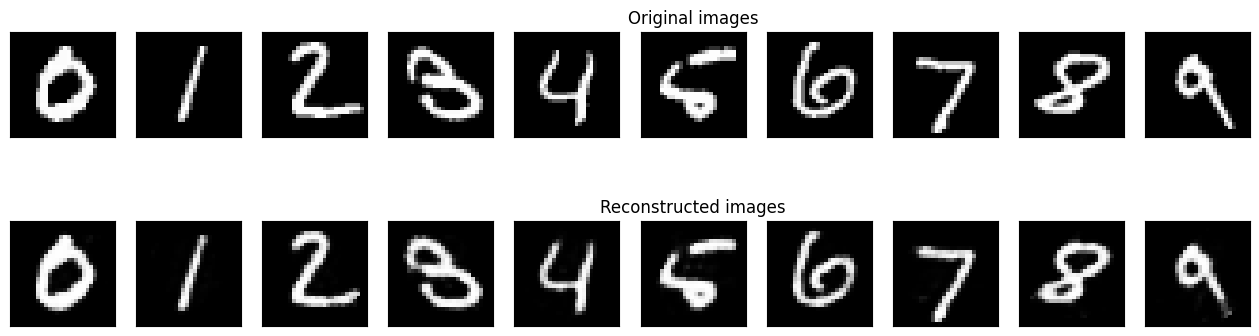

In [22]:
plot_ae_outputs(net=model,n=10)

Print the loss curve

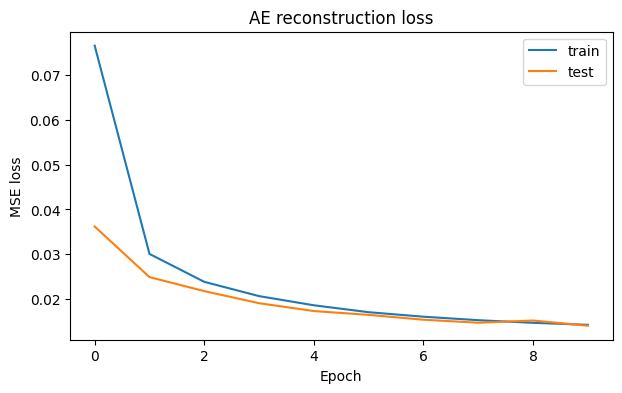

In [23]:
plt.figure(figsize=(7,4))
plt.plot(loss_train_history, label='train')
plt.plot(loss_test_history,  label='test')
plt.xlabel('Epoch'); plt.ylabel('MSE loss')
plt.title('AE reconstruction loss')
plt.legend(); plt.show()

### Latent space visualization

In [ ]:
# Uncomment if UMAP is not installed
# %pip install umap-learn

In [ ]:
import umap

Extract latent representations:

In [ ]:
# TODO
model.eval()

latent_vectors = []
labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        # Encode the images
        _, z = ...

        latent_vectors.append(z.cpu().numpy())
        labels_list.append(labels.numpy())

latent_vectors = np.concatenate(latent_vectors, axis=0)
labels_array = np.concatenate(labels_list, axis=0)

In [ ]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

latent_2d = reducer.fit_transform(latent_vectors)

print("Projected representations:", latent_2d.shape)

In [ ]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=labels_array,
    cmap="tab10",
    s=5,
    alpha=0.7
)

plt.colorbar(scatter, ticks=range(10), label="Digit class")
plt.title("UMAP projection of the autoencoder latent space")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

Questions :
- Are some classes more clearly separated than others ?
- Which classes appear to overlap ?
- Does this vizualisation suggest that the model has learned useful representations ?

### Interpolation analysis

We continue the exploration of the latent space with the notion of interpolation and generation. <br>
Interpolation between two latent representations $z_a$ and $z_b$ is defined by :
$$ \tilde{z} = (1-\alpha)*z_a + \alpha*z_b $$
with $\alpha \in [0,1]$.<br>
We define the path between $z_a$ and $z_b$ as the set of points :
$$ \gamma := \{ (1-\alpha)*z_a + \alpha*z_b;\ \alpha \in [0,1] \}  $$
We first define a function that encodes two images and return the decoded images of the interpolated representations :

In [ ]:
# TODO
def interpolate_latent(model, image_a, image_b, device, n_steps=10):
    model.eval()

    image_a = image_a.unsqueeze(0).to(device)
    image_b = image_b.unsqueeze(0).to(device)

    with torch.no_grad():
        # get latent representations z_a and z_b of the two images
        ...

        # Interpolate between latent representations
        alphas = torch.linspace(0, 1, n_steps, device=device)

        interpolated_images = []

        for alpha in alphas:
            # get interpolated representation given alpha
            z = ...

            # Decode the interpolated representation
            image = ...

            interpolated_images.append(image.cpu())

    return torch.cat(interpolated_images, dim=0)

We select two images from the test dataset and visualize the resulting sequence.

In [ ]:
images, labels = next(iter(test_loader))

# Select two images
image_a = images[0] # Select an starting point
image_b = images[9] # Select an ending point

interpolated_images = interpolate_latent(
    model,
    image_a,
    image_b,
    device,
    n_steps=10
)

fig, axes = plt.subplots(1, len(interpolated_images), figsize=(15, 2))

for i, image in enumerate(interpolated_images):
    axes[i].imshow(image.resize(28, 28), cmap="gray")
    axes[i].axis("off")
    axes[i].set_title(f"{i / (len(interpolated_images) - 1):.1f}")

plt.suptitle(
    f"Latent interpolation: digit {labels[0].item()} "
    f"to digit {labels[1].item()}"
)
plt.tight_layout()
plt.show()

Questions:
- Change the starting and ending points to obtain interpolation between two different classes. Do the same for two samples belonging the same class.
- What can you say about the decoded interpolated data ?
- Are the decoded interpolated data part of the dataset ?
- For what purpose these interpolation can be useful ?

## c) Variational autoencoder (VAE)

An Autoencoder learns a mapping:

$$
x \rightarrow z \rightarrow \hat{x}.
$$

However, the latent space does not necessarily have a well-defined
probability distribution.

Consequently, randomly sampling:

$$
z \sim \mathcal{N}(0,I)
$$

and passing $z$ through the decoder may produce poor or meaningless samples.

The variational autoencoder addresses this problem by imposing a
probabilistic structure on the latent space.

### Description

Instead of mapping an image to a single point, the encoder estimates a probability distribution from which the latent representation is sampled. <br>
A VAE combines two objectives:
- Reconstruction: produce an image similar to the input.
- Regularization: encourage the learned latent distributions to remain close to a predefined prior distribution, usually a standard Gaussian.

![vae.png](attachment:66e74a89-ef78-4ebd-936d-c2b65d11a323.png)

As the Autoencoder the VAE is composed of an encoder and a decoder, but their roles differ slightly:
- Encoder: Rather than directly producing a latent vector $z$, the encoder estimates the parameters of a Gaussian distribution. The encoder outputs two vectors $\mu(x)$ and $\log \sigma^{2}(x)$ corresponding to the mean and the log variance of the distribution.
- Decoder: the latent representation is then sampled from this distribution with $z\sim q(z|x)$ i.e $z=\mu+\sigma \odot \epsilon$ with $\epsilon\sim \mathcal{N}(0,I)$.

The architecture can be summarized as :
$$ x \rightarrow (\mu, \sigma) \rightarrow z \rightarrow \hat{x} $$

The VAE objective is then a combination of two terms:
$$
\mathcal{L}_{\mathrm{VAE}} = \mathcal{L}_{\mathrm{reconstruction}} + \mathcal{L}_{\mathrm{KL}}
$$
with $\mathcal{L}_{\mathrm{KL}} = D_{\mathrm{KL}}(q_{\phi}(z|x)\| p(z))$ is the KL divergence.<br>
The prior $p(z)$ is generally defined as $p(z)=\mathcal{N}(0,I)$.

### Implementation

Implement a VAE following the same layers as the AE:

In [ ]:
class VAE(nn.Module):

    def __init__(self, input_dim, intermediate_dim, latent_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, intermediate_dim),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(intermediate_dim, latent_dim)
        self.fc_logvar = nn.Linear(intermediate_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, intermediate_dim),
            nn.ReLU(),
            nn.Linear(intermediate_dim, input_dim),
            nn.Tanh()
        )

    def encode(self, x):
        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)

        eps = torch.randn_like(std)

        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):

        mu, logvar = self.encode(x)

        z = self.reparameterize(mu, logvar)

        x_hat = self.decode(z)

        return x_hat, mu, logvar

The VAE loss function is defined by the function :

In [ ]:
def vae_loss(x, x_hat, mu, logvar, delta=1.0):
    x = x.view(x.size(0), -1)

    reconstruction_loss = F.mse_loss(
        x_hat, x, reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + delta * kl_loss

    return total_loss, reconstruction_loss, kl_loss

Train the model. Complete the modified training functions below to train the vae:

Note: the criterion that will be used is the vae_loss function defined above.

In [ ]:
# TODO
def train_vae(model, train_loader, optimizer, criterion, device):
    # Training
    model.train()
    loss_train = []
    for batch in train_loader:
        img_batch,_ = batch
        img_batch=img_batch.view(-1, 784).to(device) #train on GPU

        # zero the parameter gradients
        ...

        # forward + backward + optimize
        ...

        # print statistics
        loss_train.append(loss.item())

    loss_train_value=np.mean(loss_train)
    return loss_train_value

def eval_vae(model, test_loader, criterion, device):
    model.eval()
    loss_eval = []
    with torch.no_grad():
        for batch in test_loader:
            img_batch, _ = batch
            img_batch = img_batch.view(-1, 784).to(device)

            # forward + backward + optimize
            ...

            loss_eval.append(loss.item())
    loss_eval_value = np.mean(loss_eval)
    return loss_eval_value

In [ ]:
epochs = 10
loss_train_history =[]
loss_test_history = []

model = VAE(input_dim=784, intermediate_dim=256, latent_dim=64)
model.to(device)

criterion = vae_loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in tqdm(range(epochs)):
    loss_train = train_vae(model, train_loader, optimizer, criterion, device)
    loss_test = eval_vae(model, test_loader, criterion, device)

    loss_train_history.append(loss_train)
    loss_test_history.append(loss_test)

    print('Epoch {}/{}: train loss: {}'.format(epoch,epochs,loss_train_history[-1]))
    print('Epoch {}/{}: test loss: {}'.format(epoch,epochs,loss_test_history[-1]))

Plot the reconstructed images:

In [ ]:
def plot_ae_outputs(net,n=10):
    plt.figure(figsize=(16,4.5))
    targets = testdata.targets.numpy()
    t_idx = {i:np.where(targets==i)[0][0] for i in range(n)}
    for i in range(n):
      ax = plt.subplot(2,n,i+1)
      img = testdata[t_idx[i]][0]
      net.eval()
      with torch.no_grad():
         rec_img  = net(img.to(device))[0]
      plt.imshow(img.view(28,28), cmap='gist_gray')
      ax.get_xaxis().set_visible(False)
      ax.get_yaxis().set_visible(False)
      if i == n//2:
        ax.set_title('Original images')
      ax = plt.subplot(2, n, i + 1 + n)
      plt.imshow(rec_img.cpu().numpy().reshape(28,28), cmap='gist_gray')
      ax.get_xaxis().set_visible(False)
      ax.get_yaxis().set_visible(False)
      if i == n//2:
         ax.set_title('Reconstructed images')
    plt.show()

In [ ]:
plot_ae_outputs(net=model,n=10)

Question:
- Compare the reconstructions with those produced by the standard autoencoder
- Are the VAE reconstruction clearer or blurrier ? Why ?

### Latent space vizualisation

Do the same as for the Autoencoder, by modifying the functions that you implemented, to visualize the latent representations with UMAP.

In [ ]:
# TODO
model.eval()

latent_vectors = []
labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        # Encode the images
        # For the VAE, we only take the µ to get the representation
        mu, _ = ...

        latent_vectors.append(mu.cpu().numpy())
        labels_list.append(labels.numpy())

latent_vectors = np.concatenate(latent_vectors, axis=0)
labels_array = np.concatenate(labels_list, axis=0)

In [ ]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

latent_2d = reducer.fit_transform(latent_vectors)

print("Projected representations:", latent_2d.shape)

In [ ]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=labels_array,
    cmap="tab10",
    s=5,
    alpha=0.7
)

plt.colorbar(scatter, ticks=range(10), label="Digit class")
plt.title("UMAP projection of the autoencoder latent space")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

Question:
- What is the difference with the latent representations of the standard autoencoder

## d) Generative Adversarial Network (GAN)

AE and VAE learn to reconstruct input images and can be used to generate new samples with methods such as interpolation. <br>
We now introduce Generative Adversarial Network (GAN) that are models specifically designed to generate samples.

For GANs, two neural networks compete against each other during training:
- Generator $G$: takes a random noise vector $z$ as input and generates a synthetic image $G(z)$,
- Discriminator $G$: takes an image as input and predicts whether it comes from the real dataset or was generated by the generator.

The generator tries to produce realistic images that fool the discriminator. The discriminator tries to distinguish real images from generated ones.

![Figures_Manuscrit-gan_archi.png](attachment:b2d32e0c-912d-4f6e-9f82-f62386323cf4.png)

As training progress, the generator should learn to produce images that resemble the training data.

#### Configuration of the two networks

The architectures of the two networks are given.

Generator network:

In [ ]:
from torch import nn
class Generator(nn.Module):
  def __init__(self, dim_z, dim_output):
    super(Generator, self).__init__()
    self.fc1 = nn.Linear(dim_z, 256)
    self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features*2)
    self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features*2)
    self.fc4 = nn.Linear(self.fc3.out_features, dim_output)
  def forward(self, x):
    x = torch.relu(self.fc1(x))
    x = torch.relu(self.fc2(x))
    x = torch.relu(self.fc3(x))
    x = torch.tanh(self.fc4(x)) # be careful with the last activation function that scales the output data
    return x

Discriminator network:

In [ ]:
class Discriminator(nn.Module):
  def __init__(self, dim_x):
      super(Discriminator, self).__init__()
      self.fc1 = nn.Linear(dim_x, 1024)
      self.fc2 = nn.Linear(self.fc1.out_features, 512)
      self.fc3 = nn.Linear(self.fc2.out_features, 256)
      self.fc4 = nn.Linear(self.fc3.out_features, 1)

  def forward(self, x):
      x = torch.relu(self.fc1(x))
      x = torch.relu(self.fc2(x))
      x = torch.relu(self.fc3(x))
      x = self.fc4(x)
      return x

### Adversarial training principle

#### Description

he generator and discriminator are trained alternately.<br>

*Step 1: Train the discriminator*<br>
The discriminator receives:
- Real images from the training dataset, which should be classified as real,
- Fake images generated by $G$, which should be classified as fake.
<br>The generator's weights are not updated during this step.

*Step 2: Train the generator*<br>
The genrator produces fake images, which are passed to the discriminator. The generator is trained to make the discriminator classify these images as real. <br>The discriminator's weights are not updated during this step.

The GAN objective is defined by the objective:
$$ \min_{G} \max_{D} V(G,D) = \min_{G} \max_{D} \mathbb{E}_{x\sim p_{\mathrm{data}}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log (1-D(G(z)))], $$
obtained by a min-max optimization problem:
$$ \max_{D} \mathcal{L}_{D} = \max_{D} \mathbb{E}_{x\sim p_{\mathrm{data}}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log (1-D(G(z)))] $$
$$ \min_G \mathcal{L}_G = \min_G \mathbb{E}_{z\sim p_z}[\log (1-D(G(z)))] $$

#### Losses and optimizers

Dimensions of the input of each network:

In [ ]:
dim_z = 128
dim_x = traindata[0][0].size(1) * traindata[0][0].size(2)

In [ ]:
dim_x # size of the flattened image

In [ ]:
G = Generator(dim_z = dim_z, dim_output = dim_x).to(device)
D = Discriminator(dim_x = dim_x).to(device)

Dual min-max optimization problem:

Note that:
- a maximization problem can be transformed into a minimization problem.  
- each model has its own optimizer and learning rate
- alternate the training of the 2 networks

Cross entropy loss:

In [ ]:
# loss
criterion = nn.BCEWithLogitsLoss()

# optimizer
lr = 0.0002
G_optimizer = torch.optim.Adam(G.parameters(), lr = lr)
D_optimizer = torch.optim.Adam(D.parameters(), lr = lr)

Complete the custom loss functions :

In [ ]:
# TODO
def discriminator_loss(real_output, fake_output,batch_size):
    real_loss = criterion(input=...,target=...) # target labels as ones for real data
    fake_loss = criterion(input=...,target=...) # target labels as zeros for fake data
    total_loss = real_loss + fake_loss
    return total_loss

In [ ]:
# TODO
def generator_loss(fake_output,batch_size):
    return criterion(input=..., target=...) # target labels as ones for fake data to fool the discriminator

#### Training

The training loop has to be implemented, as follows:

In [ ]:
# TODO
def train_step(images,batch_size):
    D.zero_grad()

    #### DISCRIMINATOR ####

    # train discriminator on real
    x_real = images.view(-1, dim_x).to(device)

    real_output = D(x_real)

    # train discriminator on fake
    z = torch.randn(batch_size, dim_z).to(device) # input noise vector

    fake_output = D(G(z).detach())

    # gradient backprop & optimize ONLY D's parameters
    D_loss = ...
    D_loss.backward()
    D_optimizer.step()

    #### GENERATOR ####

    G.zero_grad()

    z = torch.randn(batch_size, dim_z).to(device)
    fake_output = D(G(z))

    # gradient backprop & optimize ONLY G's parameters
    G_loss = ...
    G_loss.backward()
    G_optimizer.step()

    return D_loss, G_loss


Function for visualization of the data:

In [ ]:
import matplotlib

def plot(samples,epoch):
    fig = plt.figure(figsize=(4, 4))
    gs = matplotlib.gridspec.GridSpec(4, 4)
    gs.update(wspace=0.05, hspace=0.05)

    for i, sample in enumerate(samples):
        ax = plt.subplot(gs[i])
        plt.axis('off')
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_aspect('equal')
        plt.imshow(sample.reshape(28, 28)*255, cmap='Greys_r')

    plt.savefig('{}.png'.format(str(epoch).zfill(3)), bbox_inches='tight')
    plt.close('all')

    return

Launch it!

- Train alternatively the two models.
- Be aware about GAN problems
    - unstable training => vanishing gradients for the Generator
    - mode dropping => missing modes in the generated data
    - mode collapse => missing diversity in the generated modes

In [ ]:
epochs = 100
display_step = 10

In [ ]:
#torch.autograd.set_detect_anomaly(True)

In [ ]:
from tqdm import tqdm

D_loss =[]
G_loss =[]

for epoch in tqdm(np.arange(0,epochs)):
  D.train()
  G.train()
  D_loss.append([])
  G_loss.append([])

  for batch in train_loader:
      img_batch,_ = batch
      t_batch_size = img_batch.shape[0]
      t_D_loss,t_G_loss = train_step(img_batch,t_batch_size)
      D_loss[epoch].append(t_D_loss.item())
      G_loss[epoch].append(t_G_loss.item())

  D_loss[epoch]=np.mean(D_loss[epoch])
  G_loss[epoch]=np.mean(G_loss[epoch])

  if (epoch % display_step == 5 ) or epoch == 0 or (epoch==epochs-1):
    sample_z = torch.randn(16, dim_z).to(device)
    G.eval()
    with torch.no_grad():
      g_output = G(sample_z)
    plot(samples=g_output.cpu().numpy(),epoch=epoch)
    print("loss D:{}, loss G:{}".format(D_loss[epoch],G_loss[epoch]))

In [ ]:
print(device)

### Analysis of the results

In [ ]:
img=plt.imread("000.png")
plt.imshow(img)

After 100 epochs:

In [ ]:
img=plt.imread("100.png")
plt.imshow(img)

After 200 epochs:

In [ ]:
img=plt.imread("199.png")
plt.imshow(img)

Print the loss curve

In [ ]:
plt.semilogy(D_loss, label='Discriminator')
plt.semilogy(G_loss, label='Generator')
plt.xlabel('Epoch')
plt.ylabel('Average BCE Loss')
plt.legend()
plt.show()

Questions:
- What do you observe as the training progresses ?
- Is 100 epochs sufficient to train the model ? Why ?

### Bonus

Useful links:
- https://drive.google.com/file/d/1-QHdUJ21SrjVLDXHJ-iOWIKASKbIKojE/view
- https://medium.com/@jonathan_hui/gan-why-it-is-so-hard-to-train-generative-advisory-networks-819a86b3750b
- https://distill.pub/2019/gan-open-problems/#convergence
- https://medium.com/beyondminds/advances-in-generative-adversarial-networks-7bad57028032
- https://github.com/soumith/ganhacks/
- https://developers.google.com/machine-learning/gan/problems


GAN LAB : https://poloclub.github.io/ganlab/
Book: https://www.manning.com/books/gans-in-action

GAN first paper: Goodfellow, I., Pouget-Abadie, J., Mirza, M., Xu, B., Warde-Farley, D., Ozair, S., ... & Bengio, Y. (2014). Generative adversarial nets. In Advances in neural information processing systems (pp. 2672-2680).
Tutorial: https://arxiv.org/abs/1701.00160

DCGAN: Radford, A., Metz, L., & Chintala, S. (2015). Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks. CoRR, abs/1511.06434.
Tutorial: https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html

Applications: https://jonathan-hui.medium.com/gan-some-cool-applications-of-gans-4c9ecca35900, https://github.com/nashory/gans-awesome-applications

Try to adjust the models

About GAN, you can follow the tips (see medium blogs) such as:
- Change normal distribution for uniform distribution
- Change the output function of the generator for tanh activation
- Replace ReLu by LeakyReLu
- Add regularization like Dropout, BatchNorm
- Add variability in the input (gaussian noises)
- Smooth the labels / Flip the labels
- Make deeper the architecture of both generator and discriminator networks
- ...

You can also have a look at the original paper.

Go further: Change the models by integrating a convolutional network (refer to DCGAN: https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html)


**Currently, the state-of-the-art GAN is the WGAN-GP: Wasserstein GAN with Gradient Penalty (https://arxiv.org/pdf/1704.00028.pdf)**


In [ ]:
# Tuning of the hyper parameters of the GAN

# TODO